In [2]:
from datasets import load_dataset
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dataset = load_dataset(
    "changelinglab/librispeech-segment",
    split="train.clean.100",
    streaming=True,
)

dataset = dataset.decode(False)

example = next(iter(dataset))

print(example["text"])
print(example["audio"]["path"])
print("Duration:", example["duration"])

THERE WERE NO FAIRIES AND HOBGOBLINS ABOUT
7635-105409-0022.flac
Duration: 2.75


In [4]:
audio_bytes = example["audio"]["bytes"]

audio_path = "../data/raw/test_audio.flac"

with open(audio_path, "wb") as f:
    f.write(audio_bytes)

print("Saved:", audio_path)
print("Size:", len(audio_bytes), "bytes")

Saved: ../data/raw/test_audio.flac
Size: 62558 bytes


In [5]:
audio, sample_rate = sf.read(audio_path)

print("Sample rate:", sample_rate)
print("Number of samples:", len(audio))
print("Duration:", len(audio) / sample_rate, "seconds")
print("Audio shape:", audio.shape)

Sample rate: 16000
Number of samples: 44000
Duration: 2.75 seconds
Audio shape: (44000,)


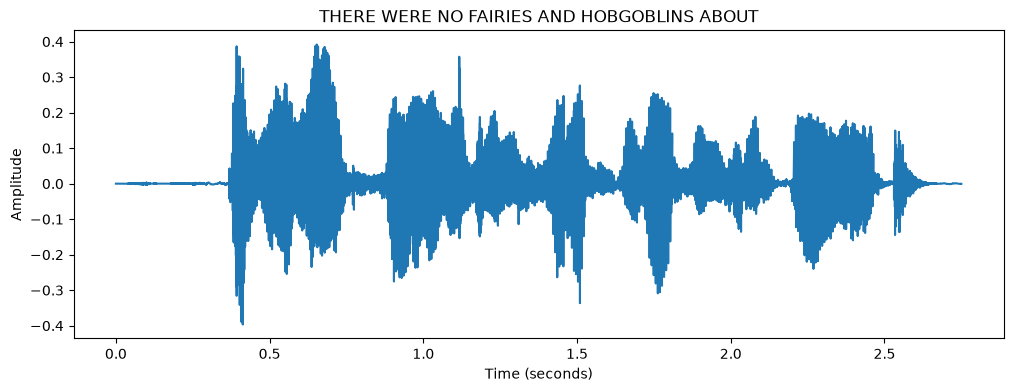

In [6]:
time = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title(example["text"])
plt.show()

In [7]:
phones = example["phones"]
starts = example["phone_starts"]
ends = example["phone_ends"]

print(len(phones), len(starts), len(ends))

for phone, start, end in zip(phones, starts, ends):
    print(f"{start:.2f} - {end:.2f}: {phone}")

32 32 32
0.00 - 0.31: [SIL]
0.31 - 0.38: DH
0.38 - 0.41: EH
0.41 - 0.44: R
0.44 - 0.50: W
0.50 - 0.58: ER
0.58 - 0.65: N
0.65 - 0.75: OW
0.75 - 0.89: F
0.89 - 0.99: EH
0.99 - 1.07: R
1.07 - 1.13: IY
1.13 - 1.20: Z
1.20 - 1.25: AH
1.25 - 1.28: N
1.28 - 1.32: D
1.32 - 1.42: HH
1.42 - 1.53: AA
1.53 - 1.61: B
1.61 - 1.66: G
1.66 - 1.81: AA
1.81 - 1.87: B
1.87 - 1.90: L
1.90 - 1.93: IH
1.93 - 1.97: N
1.97 - 2.05: Z
2.05 - 2.13: AH
2.13 - 2.22: B
2.22 - 2.46: AW
2.46 - 2.67: T
2.67 - 2.73: [SIL]
2.73 - 2.75: [SIL]


In [17]:
unique_phones = sorted(set(phones))

print("Number of unique phonemes:", len(unique_phones))
print(unique_phones)

Number of unique phonemes: 21
['AA', 'AH', 'AW', 'B', 'D', 'DH', 'EH', 'ER', 'F', 'G', 'HH', 'IH', 'IY', 'L', 'N', 'OW', 'R', 'T', 'W', 'Z', '[SIL]']


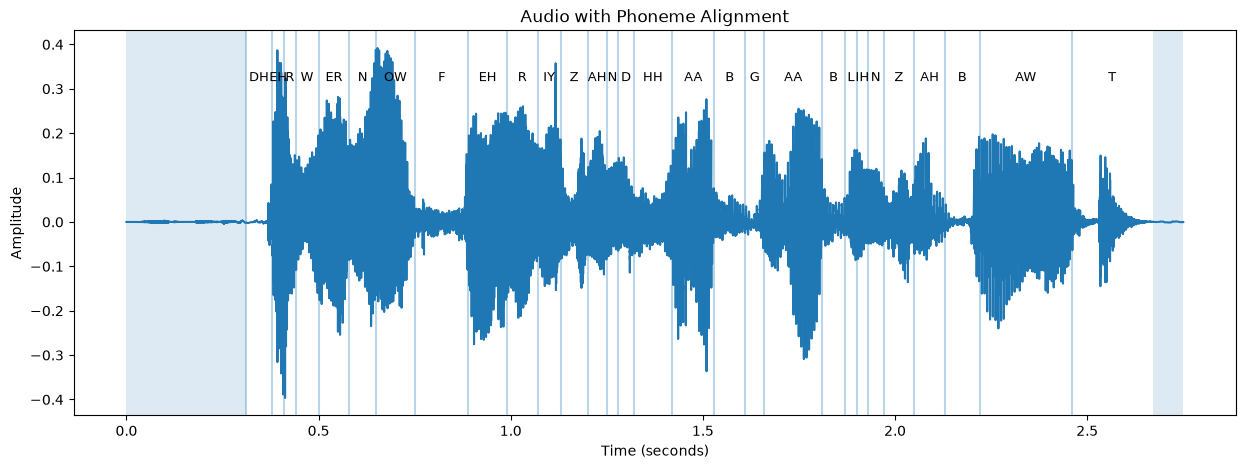

In [9]:
plt.figure(figsize=(15, 5))
plt.plot(time, audio)

for phone, start, end in zip(phones, starts, ends):
    if phone == "[SIL]":
        plt.axvspan(start, end, alpha=0.15)
    else:
        plt.axvline(start, alpha=0.3)
        plt.text(
            (start + end) / 2,
            0.8 * np.max(np.abs(audio)),
            phone,
            ha="center",
            fontsize=9
        )

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio with Phoneme Alignment")
plt.show()

In [11]:
# 20ms frames

frame_duration = 0.02  # 20 ms

frame_starts = np.arange(0, example["duration"], frame_duration)

frame_labels = []

for start in frame_starts:
    # Use the middle of the frame to decide its phoneme
    midpoint = start + frame_duration / 2

    label = "[UNKNOWN]"

    for phone, phone_start, phone_end in zip(phones, starts, ends):
        if phone_start <= midpoint < phone_end:
            label = phone
            break

    frame_labels.append(label)

print("Number of frames:", len(frame_labels))

for start, label in zip(frame_starts[:30], frame_labels[:30]):
    print(f"{start:.2f}s -> {label}")

Number of frames: 138
0.00s -> [SIL]
0.02s -> [SIL]
0.04s -> [SIL]
0.06s -> [SIL]
0.08s -> [SIL]
0.10s -> [SIL]
0.12s -> [SIL]
0.14s -> [SIL]
0.16s -> [SIL]
0.18s -> [SIL]
0.20s -> [SIL]
0.22s -> [SIL]
0.24s -> [SIL]
0.26s -> [SIL]
0.28s -> [SIL]
0.30s -> DH
0.32s -> DH
0.34s -> DH
0.36s -> DH
0.38s -> EH
0.40s -> R
0.42s -> R
0.44s -> W
0.46s -> W
0.48s -> W
0.50s -> ER
0.52s -> ER
0.54s -> ER
0.56s -> ER
0.58s -> N


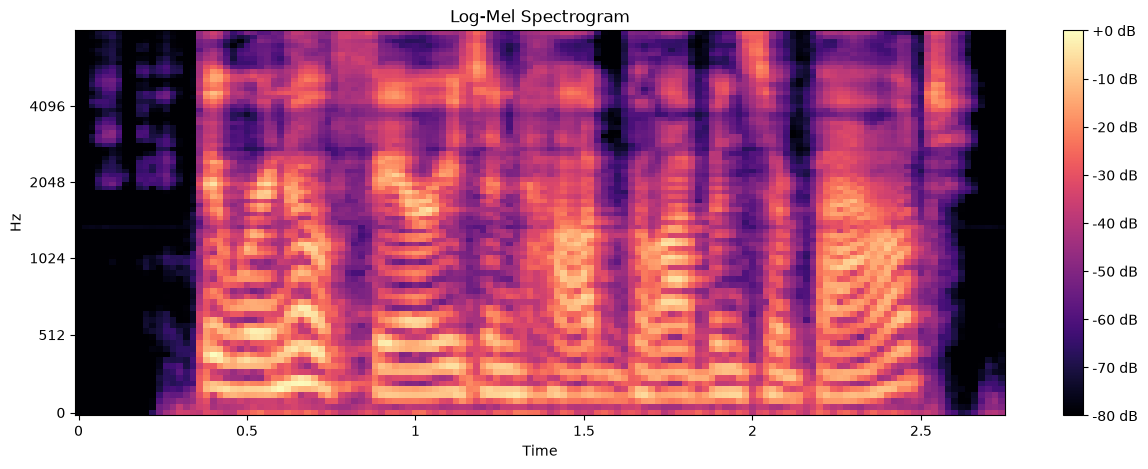

In [12]:
import librosa
import librosa.display

mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sample_rate,
    n_fft=1024,
    hop_length=320,
    n_mels=80
)

log_mel = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(15, 5))
librosa.display.specshow(
    log_mel,
    sr=sample_rate,
    hop_length=320,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram")
plt.show()

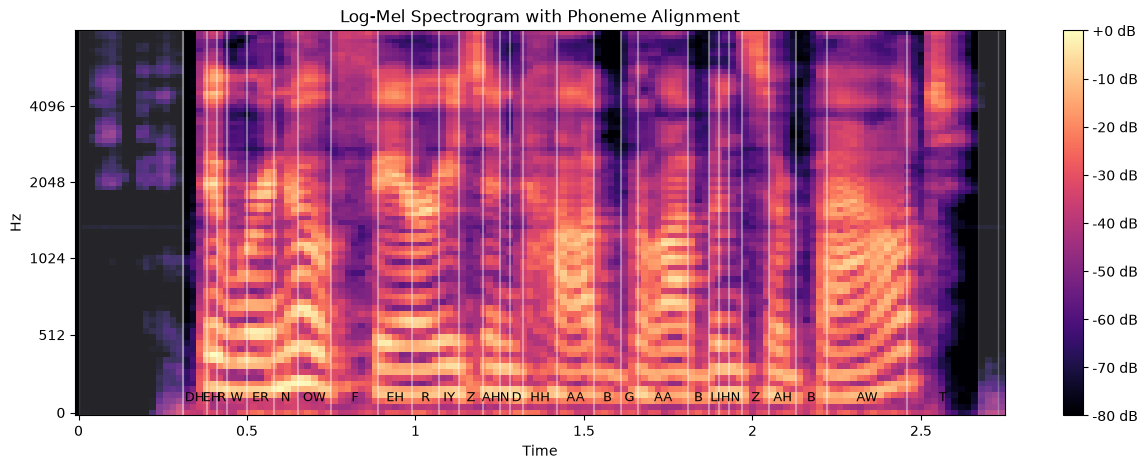

In [16]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    log_mel,
    sr=sample_rate,
    hop_length=320,
    x_axis="time",
    y_axis="mel"
)

# Draw phoneme boundaries
for phone, start, end in zip(phones, starts, ends):
    if phone == "[SIL]":
        plt.axvspan(start, end, alpha=0.15, color="white")
    else:
        plt.axvline(start, alpha=0.4, color="white")
        plt.text(
            (start + end) / 2,
            75,
            phone,
            ha="center",
            fontsize=9
        )

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram with Phoneme Alignment")
plt.show()